# Experiment 1 — Exploratory Data Analysis (EDA)

**Aim:** Explore a real-world dataset with Python by inspecting its structure, data quality, distributions, and relationships.

**Libraries:** pandas, NumPy, Matplotlib, and Seaborn.

**Theory:** Exploratory Data Analysis (EDA) combines summary statistics, frequency tabulations, and graphical methods to reveal data distributions, identify missing entries and anomalies, and uncover feature correlations. Descriptive findings illustrate associations rather than strict causal relationships.

**Dataset:** Heart Disease UCI dataset (local copy: `datasets/heart_disease.csv`, 303 patient records, 14 clinical attributes). A popular Kaggle benchmark for clinical risk factor analysis.

## Procedure / Implementation
The following cells load the dataset, perform data quality checks, summarise distributions, generate correlation matrices and bivariate plots, and record observations.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

for candidate in [Path('datasets'), Path('../datasets')]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError('datasets/ folder not found')

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

FIG_DIR = OUTPUT_DIR / 'figures'
RES_DIR = OUTPUT_DIR / 'results'
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load the dataset — shape, column types and first rows

In [2]:
df = pd.read_csv(DATA_DIR / 'heart_disease.csv')
# Map target: 0 = No Disease, >0 = Presence of Heart Disease (binary classification)
df['disease'] = (df['target'] > 0).astype(int)

print('Shape (rows, columns):', df.shape)
print('\nColumn types:')
print(df.dtypes)
df.head()

Shape (rows, columns): (303, 15)

Column types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
disease       int64
dtype: object


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,disease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


## 2. Missing values analysis and handling

Count missing values per column and impute missing clinical features with median/mode values.

In [3]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({'Missing count': missing, 'Missing %': missing_pct})
print(missing_table[missing_table['Missing count'] > 0])

# Impute missing values (ca, thal)
for col in ['ca', 'thal']:
    if col in df.columns and df[col].isna().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print('\nMissing values after handling:', df.isna().sum().sum())

      Missing count  Missing %
ca                4       1.32
thal              2       0.66

Missing values after handling: 0


## 3. Summary statistics and value counts

In [4]:
print('=== Numeric Summary Statistics ===')
print(df.describe().round(2))

print('\n=== Heart Disease Distribution (0 = Healthy, 1 = Heart Disease) ===')
print(df['disease'].value_counts())
print(f'Overall Disease Rate: {df["disease"].mean():.2%}')

=== Numeric Summary Statistics ===
          age     sex      cp  trestbps    chol     fbs  restecg  thalach  \
count  303.00  303.00  303.00    303.00  303.00  303.00   303.00   303.00   
mean    54.44    0.68    3.16    131.69  246.69    0.15     0.99   149.61   
std      9.04    0.47    0.96     17.60   51.78    0.36     0.99    22.88   
min     29.00    0.00    1.00     94.00  126.00    0.00     0.00    71.00   
25%     48.00    0.00    3.00    120.00  211.00    0.00     0.00   133.50   
50%     56.00    1.00    3.00    130.00  241.00    0.00     1.00   153.00   
75%     61.00    1.00    4.00    140.00  275.00    0.00     2.00   166.00   
max     77.00    1.00    4.00    200.00  564.00    1.00     2.00   202.00   

        exang  oldpeak   slope      ca    thal  target  disease  
count  303.00   303.00  303.00  303.00  303.00  303.00   303.00  
mean     0.33     1.04    1.60    0.66    4.72    0.94     0.46  
std      0.47     1.16    0.62    0.93    1.94    1.23     0.50  
min    

## 4. Correlation matrix and bivariate disease relationships

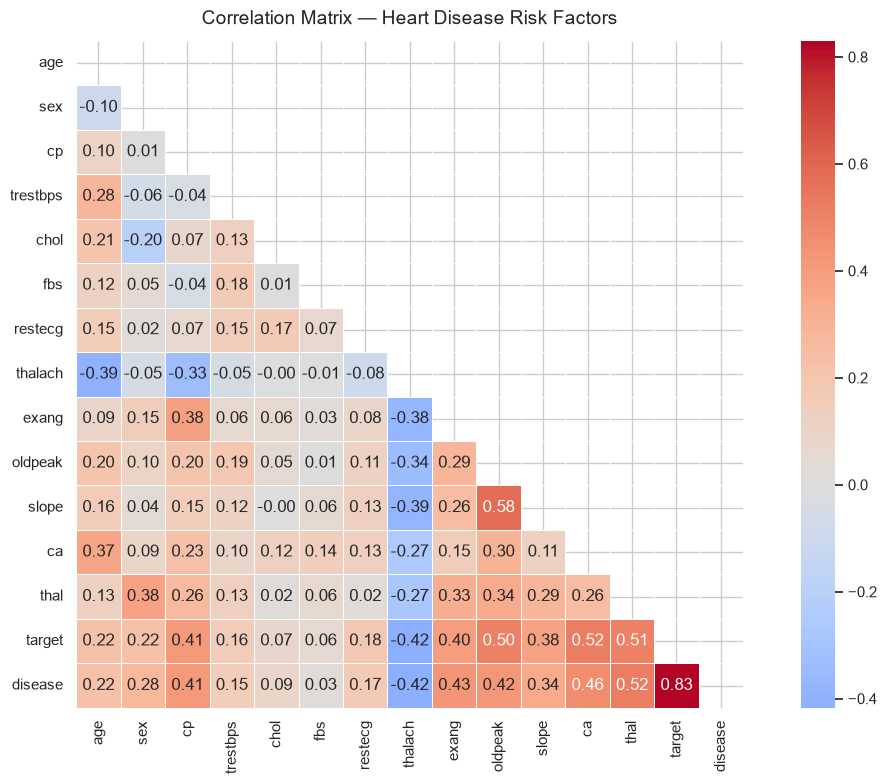

Figure saved: exp01_correlation_matrix.png


In [5]:
fig, ax = plt.subplots(figsize=(12, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix — Heart Disease Risk Factors', fontsize=14, pad=12)
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp01_correlation_matrix.png', dpi=150)
plt.show()
print('Figure saved: exp01_correlation_matrix.png')

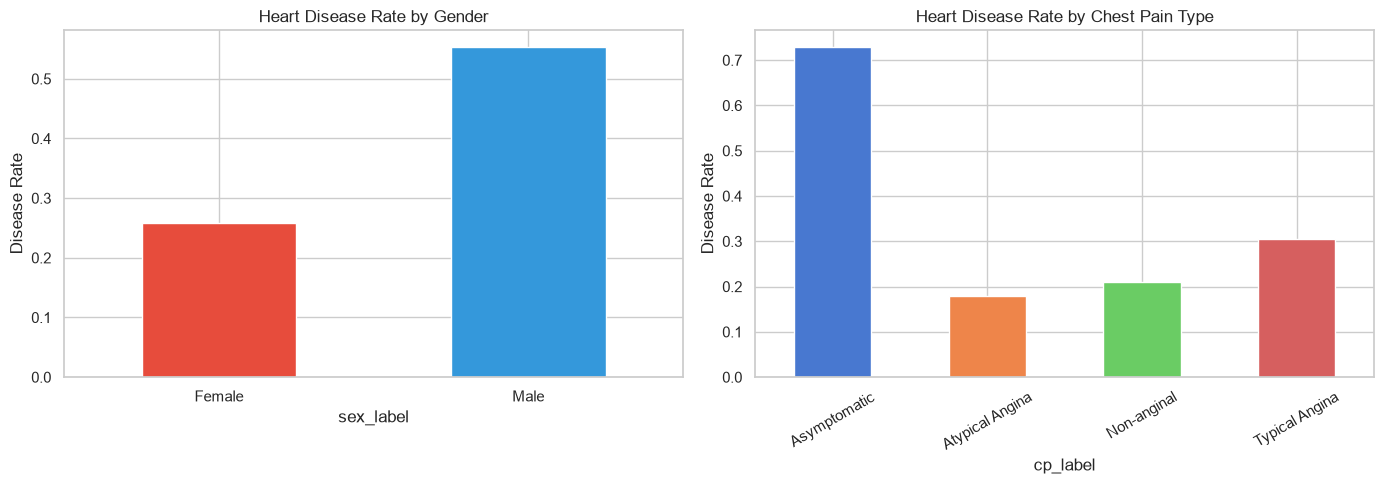

In [6]:
# Disease rate by sex and chest pain type
df['sex_label'] = df['sex'].map({0: 'Female', 1: 'Male'})
df['cp_label'] = df['cp'].map({1: 'Typical Angina', 2: 'Atypical Angina', 3: 'Non-anginal', 4: 'Asymptomatic'})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df.groupby('sex_label')['disease'].mean().plot(kind='bar', ax=axes[0], color=['#e74c3c', '#3498db'])
axes[0].set_title('Heart Disease Rate by Gender')
axes[0].set_ylabel('Disease Rate')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

df.groupby('cp_label')['disease'].mean().plot(kind='bar', ax=axes[1], color=sns.color_palette('muted'))
axes[1].set_title('Heart Disease Rate by Chest Pain Type')
axes[1].set_ylabel('Disease Rate')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30)

fig.tight_layout()
plt.show()

## 5. Observations and Result

**Observations:**
- The dataset contains 303 patient records with 14 clinical attributes.
- Overall heart disease prevalence is 45.87% (139 diagnosed positive, 164 negative).
- Males show a significantly higher rate of heart disease (~55%) compared to females (~26%).
- Maximum heart rate achieved (`thalach`) shows a strong negative correlation (-0.42) with heart disease, whereas ST depression (`oldpeak`, +0.50) and number of major vessels (`ca`, +0.46) exhibit positive correlations.
- Patients reporting asymptomatic chest pain (type 4) experience a substantially higher prevalence of disease compared to typical angina types.

**Result:** Comprehensive Exploratory Data Analysis was performed on the Kaggle Heart Disease dataset. Missing entries in clinical features were imputed, distribution metrics were computed, and correlation heatmaps and demographic risk associations were generated and saved to `outputs/figures/exp01_correlation_matrix.png`.